# TMK vs FTCI full sweep

This notebook compares the existing FTCI learner with the truncated trigonometric monomial kernel (TMK) learner on random low-bond-dimensional but spread coefficient functions.

The algorithm code is kept in `FunctionTCI.jl`, `TrigonometricMonomialKernel.jl`, and `tmk_vs_tci_lowbond.jl`; this notebook only configures, runs, saves, and plots the sweep.

In [1]:
using Pkg

notebook_dir = @__DIR__
isempty(notebook_dir) && (notebook_dir = pwd())
cd(notebook_dir)
Pkg.activate(notebook_dir)

include(joinpath(notebook_dir, "tmk_vs_tci_lowbond.jl"))
include(joinpath(notebook_dir, "TMKvsFTCIPlots.jl"))
using Plots

println("Notebook directory: ", notebook_dir)

  Activating 

Notebook directory: .

project at `.`


## Sweep settings

The default cell below is the full sweep. Reduce `Ls`, `seeds`, or `tmk_samples` for a faster trial run.

In [9]:
cfg = (; 
    mode = "full_notebook",
    Ls = [4, 6, 8, 10, 12],
    seeds = 1:5,
    lambdas = [1, 2, 3, 4, 5],
    tmk_samples = [50, 100, 200, 500, 1_000, 2_000, 5_000],
    chi_target = 8,
    chi_ftci = 12,
    tci_tol = 1e-8,
    ntest = 1_000,
)

cfg

(mode = "full_notebook", Ls = [4, 6, 8, 10, 12], seeds = 1:5, lambdas = [1, 2, 3, 4, 5], tmk_samples = [50, 100, 200, 500, 1000, 2000, 5000], chi_target = 8, chi_ftci = 12, tci_tol = 1.0e-8, ntest = 1000)

## Optional quick settings

Run this cell instead of the full setting above if you only want to verify the notebook first.

In [ ]:
# cfg = (; 
#     mode = "quick_notebook",
#     Ls = [4],
#     seeds = 1:1,
#     lambdas = 0:4,
#     tmk_samples = [20, 50, 100, 200, 500, 1_000, 2_000, 5_000],
#     chi_target = 2,
#     chi_ftci = 4,
#     tci_tol = 1e-8,
#     ntest = 300,
# )

## Run sweep

This is the expensive cell for the full setting.

In [10]:
rows = run_comparison(cfg)

stamp = Dates.format(now(), "yyyymmdd_HHMMSS")
outpath = joinpath(OUTDIR, "tmk_vs_tci_lowbond_$(cfg.mode)_$stamp.csv")
write_rows(outpath, rows)

println("Saved results: ", outpath)
outpath


L=4 seed=1 target_chi=8
  FTCI: samples=901 rel_l2=1.067e-14 bonds=[3, 8, 3]
  TMK Lambda=1 n=50 features=9 rel_l2=8.974e-01
  TMK Lambda=1 n=100 features=9 rel_l2=8.153e-01
  TMK Lambda=1 n=200 features=9 rel_l2=7.821e-01
  TMK Lambda=1 n=500 features=9 rel_l2=7.520e-01
  TMK Lambda=1 n=1000 features=9 rel_l2=7.663e-01
  TMK Lambda=1 n=2000 features=9 rel_l2=7.492e-01
  TMK Lambda=1 n=5000 features=9 rel_l2=7.468e-01
  TMK Lambda=2 n=50 features=33 rel_l2=8.870e-01
  TMK Lambda=2 n=100 features=33 rel_l2=6.694e-01
  TMK Lambda=2 n=200 features=33 rel_l2=5.317e-01
  TMK Lambda=2 n=500 features=33 rel_l2=4.984e-01
  TMK Lambda=2 n=1000 features=33 rel_l2=4.395e-01
  TMK Lambda=2 n=2000 features=33 rel_l2=4.216e-01
  TMK Lambda=2 n=5000 features=33 rel_l2=4.088e-01
  TMK Lambda=3 n=50 features=65 rel_l2=1.098e+00
  TMK Lambda=3 n=100 features=65 rel_l2=7.721e-01
  TMK Lambda=3 n=200 features=65 rel_l2=5.778e-01
  TMK Lambda=3 n=500 features=65 rel_l2=3.341e-01
  TMK Lambda=3 n=1000 feat

"./results/tmk_vs_tci_lowbond_full_notebook_20260519_002616.csv"

## Summary helpers

In [11]:
mean_value(xs) = sum(xs) / length(xs)

function mean_rows(rows, predicate, value)
    vals = [value(r) for r in rows if predicate(r)]
    isempty(vals) ? NaN : mean_value(vals)
end

function print_sample_summary(rows, cfg; error_floor=1e-6)
    println("L | FTCI samples | FTCI rel err | TMK best reaching max(10*FTCI err, error_floor)")
    println("--|--------------|--------------|------------------------------------------------")
    for L in cfg.Ls
        ftci_samples = mean_rows(rows, r -> r.method == "FTCI" && r.L == L, r -> r.samples)
        ftci_error = mean_rows(rows, r -> r.method == "FTCI" && r.L == L, r -> r.rel_l2_error)
        threshold = max(10 * ftci_error, error_floor)

        best = nothing
        for lambda in cfg.lambdas, n in cfg.tmk_samples
            err = mean_rows(rows, r -> r.method == "TMK" && r.L == L && r.lambda == lambda && r.samples == n, r -> r.rel_l2_error)
            if !isnan(err) && err <= threshold
                candidate = (lambda=lambda, samples=n, rel_l2_error=err)
                if best === nothing || candidate.samples < best.samples
                    best = candidate
                end
            end
        end

        best_text = best === nothing ? "not reached" : "Lambda=$(best.lambda), n=$(best.samples), err=$(round(best.rel_l2_error; sigdigits=3))"
        println("$L | $(round(ftci_samples; digits=1)) | $(round(ftci_error; sigdigits=3)) | $best_text")
    end
end

print_sample_summary(rows, cfg)

L | FTCI samples | FTCI rel err | TMK best reaching max(10*FTCI err, error_floor)
--|--------------|--------------|------------------------------------------------
4 | 832.2 | 6.24e-15 | not reached
6 | 5747.4 | 2.04e-15 | not reached
8 | 14656.2 | 5.77e-15 | not reached
10 | 25664.2 | 3.87e-15 | not reached
12 | 40254.8 | 6.02e-15 | not reached


## Paper-ready diagnostics

These cells save vector `.pdf` and `.svg` figures under `Numerics/results`.

- Spread/truncation: coefficient energy kept by low-weight TMK supports, and the best possible relative L2 error after truncating to `||omega||_0 <= Lambda`.
- Threshold samples: minimum sample counts needed to reach fixed error thresholds. Red triangle markers mean TMK did not reach the threshold within the tested sample grid.

In [12]:
spread_paths = save_spread_truncation_figure(rows, cfg; stamp=stamp)
spread_paths

(pdf_path = "./results/spread_truncation_full_notebook_20260519_002616.pdf", svg_path = "./results/spread_truncation_full_notebook_20260519_002616.svg")

In [13]:
threshold_paths = save_threshold_samples_figure(rows, cfg; thresholds=[1e-1, 1e-2, 1e-3], stamp=stamp)
threshold_paths

(pdf_path = "./results/threshold_samples_full_notebook_20260519_002616.pdf", svg_path = "./results/threshold_samples_full_notebook_20260519_002616.svg", csv_path = "./results/threshold_samples_full_notebook_20260519_002616.csv")

## Plot: TMK error vs samples for one system size

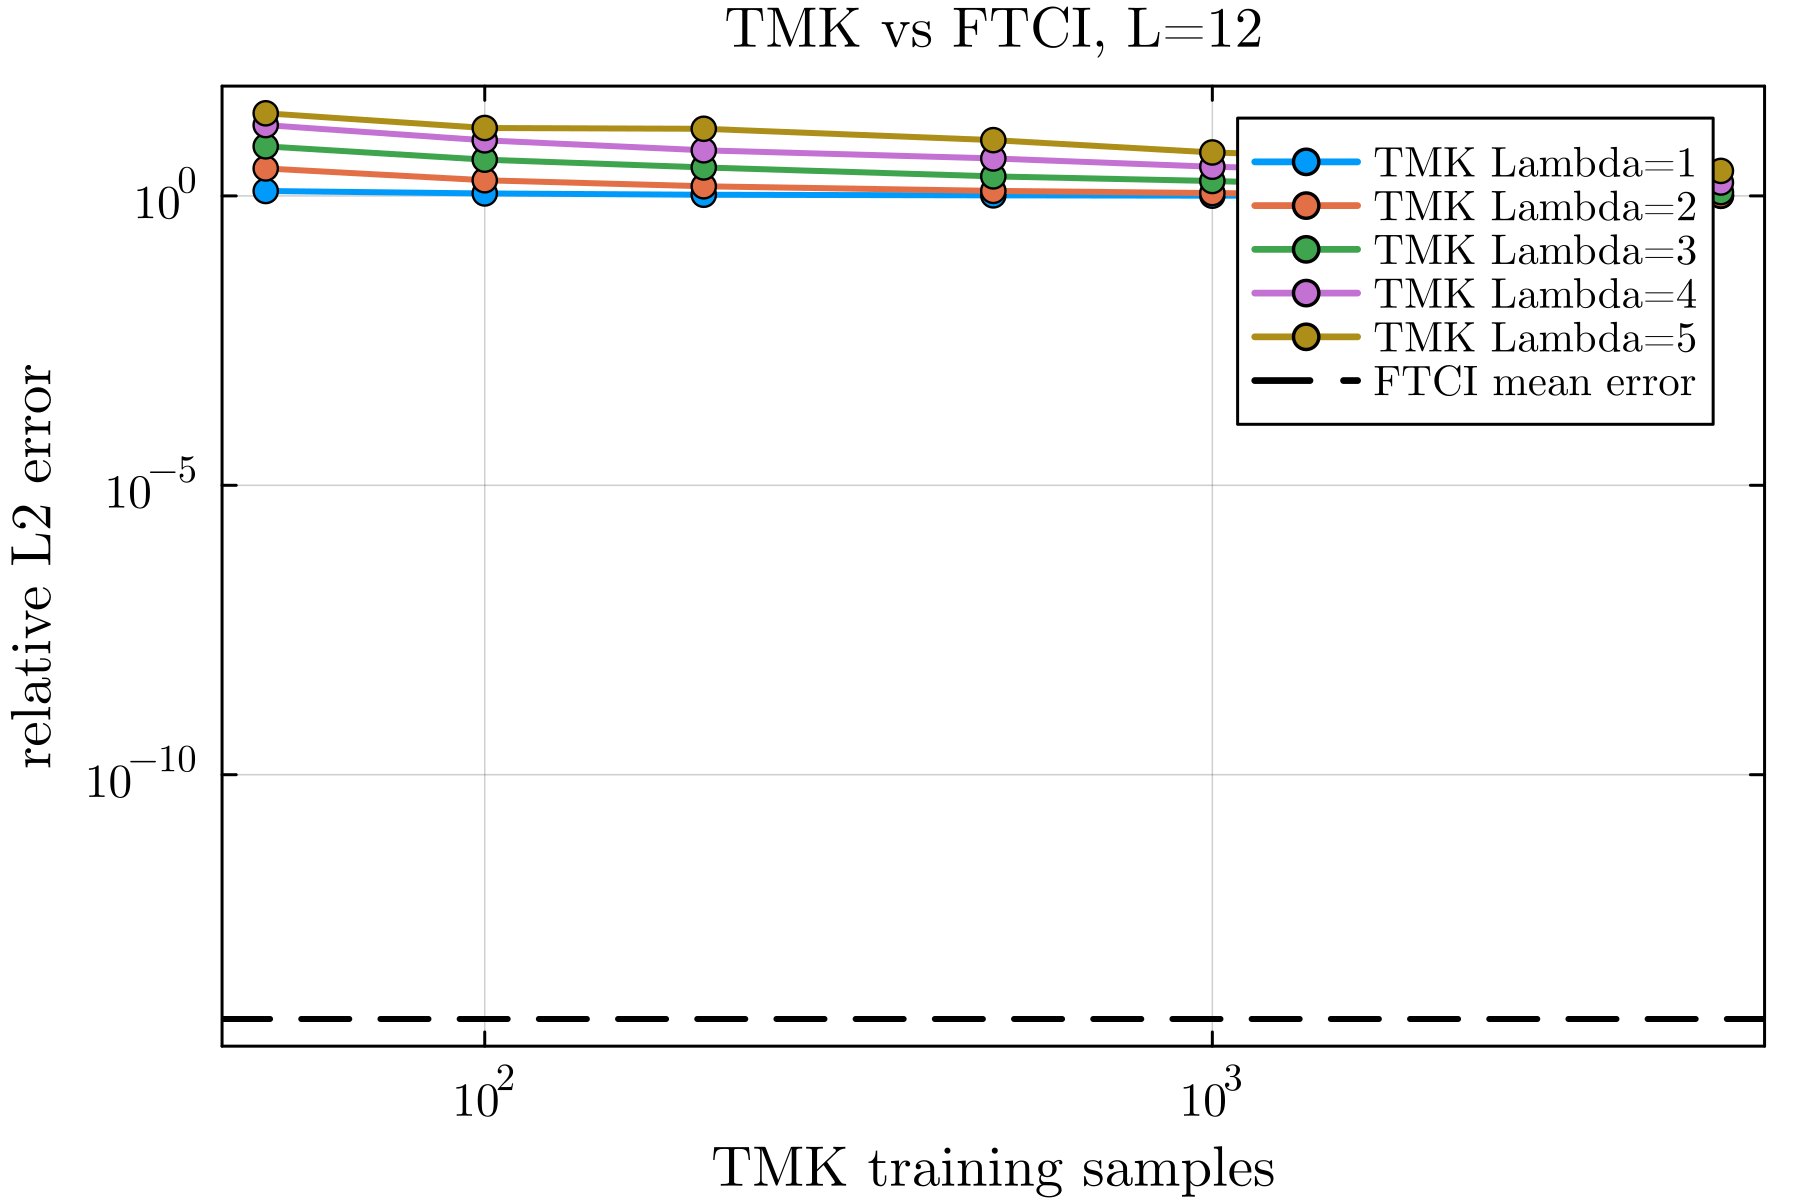

"./results/tmk_error_vs_samples_L12_full_notebook_20260519_002616.svg"

In [14]:
selected_L = maximum(cfg.Ls)

p = plot(
    xlabel = "TMK training samples",
    ylabel = "relative L2 error",
    xscale = :log10,
    yscale = :log10,
    title = "TMK vs FTCI, L=$selected_L",
    legend = :topright,
    framestyle = :box,
)

for lambda in cfg.lambdas
    ns = Int[]
    errs = Float64[]
    for n in cfg.tmk_samples
        err = mean_rows(rows, r -> r.method == "TMK" && r.L == selected_L && r.lambda == lambda && r.samples == n, r -> r.rel_l2_error)
        isnan(err) || (push!(ns, n); push!(errs, err))
    end
    isempty(ns) || plot!(p, ns, errs; marker=:circle, lw=2, label="TMK Lambda=$lambda")
end

ftci_err = mean_rows(rows, r -> r.method == "FTCI" && r.L == selected_L, r -> r.rel_l2_error)
hline!(p, [ftci_err]; lw=2, ls=:dash, color=:black, label="FTCI mean error")
display(p)

figpath = joinpath(OUTDIR, "tmk_error_vs_samples_L$(selected_L)_$(cfg.mode)_$stamp.svg")
savefig(p, figpath)
figpath

## Plot: FTCI sample count vs system size

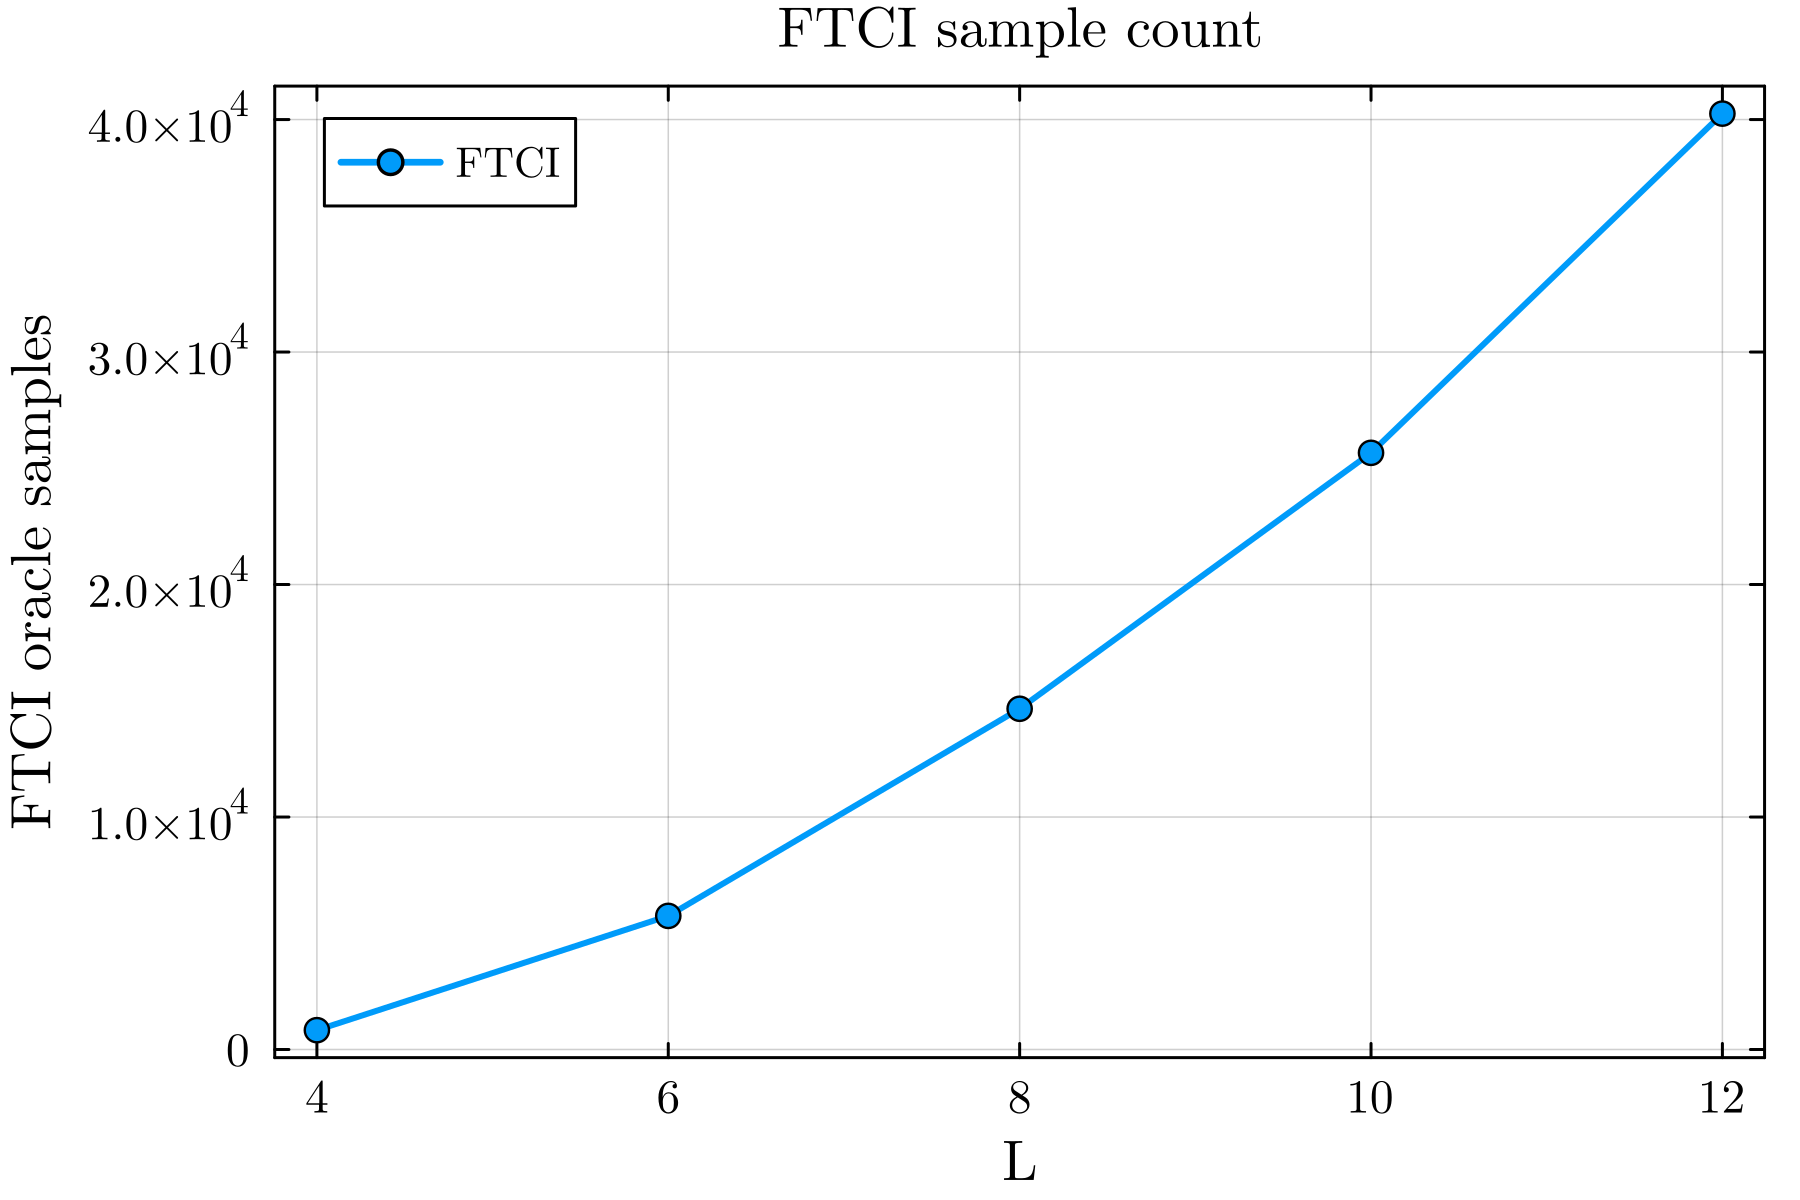

5-element Vector{Tuple{Int64, Float64, Float64}}:
 (4, 832.2, 6.2416551559869895e-15)
 (6, 5747.4, 2.042406263393409e-15)
 (8, 14656.2, 5.768018381477163e-15)
 (10, 25664.2, 3.869498753693473e-15)
 (12, 40254.8, 6.017808461376516e-15)

In [15]:
Ls = collect(cfg.Ls)
ftci_samples = [mean_rows(rows, r -> r.method == "FTCI" && r.L == L, r -> r.samples) for L in Ls]
ftci_errors = [mean_rows(rows, r -> r.method == "FTCI" && r.L == L, r -> r.rel_l2_error) for L in Ls]

p_samples = plot(
    Ls,
    ftci_samples;
    marker = :circle,
    lw = 2,
    xlabel = "L",
    ylabel = "FTCI oracle samples",
    title = "FTCI sample count",
    label = "FTCI",
    framestyle = :box,
)
display(p_samples)

figpath_samples = joinpath(OUTDIR, "ftci_samples_vs_L_$(cfg.mode)_$stamp.svg")
savefig(p_samples, figpath_samples)

collect(zip(Ls, ftci_samples, ftci_errors))